In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../dataset/PS_20174392719_1491204439457_log.csv", nrows=100000)

In [4]:
df = pd.read_csv("../dataset/PS_20174392719_1491204439457_log.csv")

In [5]:
df.shape

(6362620, 11)

In [5]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [7]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [8]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [11]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [13]:
fraud_percentage = df['isFraud'].mean() * 100

fraud_percentage

np.float64(0.12908204481801522)

In [14]:
pd.crosstab(df['type'], df['isFraud'], normalize='index') * 100

isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


In [15]:
fraud_transactions = df[df['isFraud'] == 1]

total_fraud_amount = fraud_transactions['amount'].sum()

total_fraud_amount

np.float64(12056415427.84)

In [16]:
average_fraud_amount = fraud_transactions['amount'].mean()

average_fraud_amount

np.float64(1467967.2991403872)

In [17]:
df.groupby('isFraud')['amount'].mean()

isFraud
0    1.781970e+05
1    1.467967e+06
Name: amount, dtype: float64

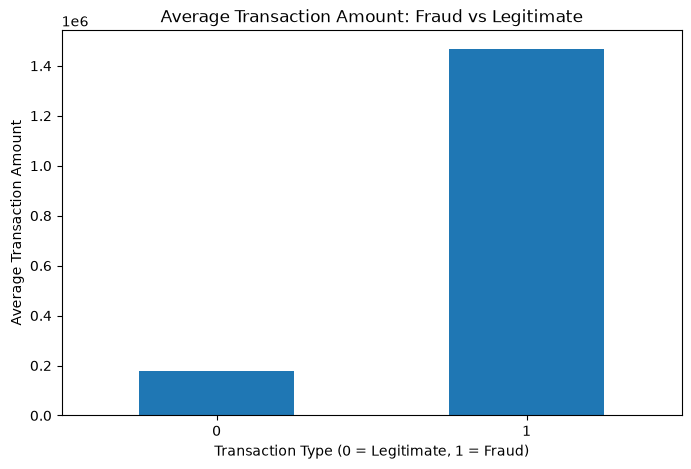

In [18]:
fraud_comparison = df.groupby('isFraud')['amount'].mean()

fraud_comparison.plot(
    kind='bar',
    title='Average Transaction Amount: Fraud vs Legitimate',
    xlabel='Transaction Type (0 = Legitimate, 1 = Fraud)',
    ylabel='Average Transaction Amount',
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.show()

In [19]:
fraud_by_type = df[df['isFraud'] == 1].groupby('type').agg(
    fraud_count=('isFraud', 'count'),
    total_fraud_amount=('amount', 'sum'),
    average_fraud_amount=('amount', 'mean')
)

fraud_by_type

,fraud_count,total_fraud_amount,average_fraud_amount
type,,,
CASH_OUT,4116,5.989202e+09,1.455103e+06
TRANSFER,4097,6.067213e+09,1.480892e+06


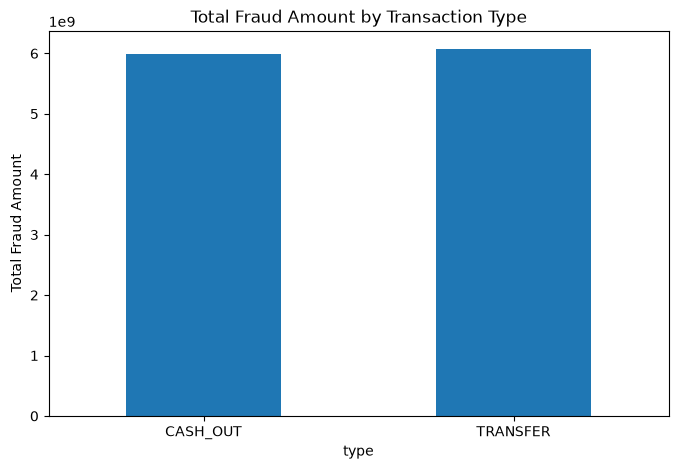

In [20]:
fraud_by_type['total_fraud_amount'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Fraud Amount by Transaction Type',
    ylabel='Total Fraud Amount'
)

plt.xticks(rotation=0)
plt.show()

In [20]:
fraud_transactions['amount'].describe()

count    8.213000e+03
mean     1.467967e+06
std      2.404253e+06
min      0.000000e+00
25%      1.270913e+05
50%      4.414234e+05
75%      1.517771e+06
max      1.000000e+07
Name: amount, dtype: float64

In [21]:
fraud_transactions['type'].value_counts()

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

In [22]:
zero_amount_fraud = fraud_transactions[
    fraud_transactions['amount'] == 0
]

zero_amount_fraud.shape

(16, 11)

In [23]:
zero_amount_fraud.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
2736447,212,CASH_OUT,0.0,C1510987794,0.0,0.0,C1696624817,0.00,0.00,1,0
3247298,250,CASH_OUT,0.0,C521393327,0.0,0.0,C480398193,0.00,0.00,1,0
3760289,279,CASH_OUT,0.0,C539112012,0.0,0.0,C1106468520,538547.63,538547.63,1,0
5563714,387,CASH_OUT,0.0,C1294472700,0.0,0.0,C1325541393,7970766.57,7970766.57,1,0
5996408,425,CASH_OUT,0.0,C832555372,0.0,0.0,C1462759334,76759.90,76759.90,1,0
5996410,425,CASH_OUT,0.0,C69493310,0.0,0.0,C719711728,2921531.34,2921531.34,1,0
6168500,554,CASH_OUT,0.0,C10965156,0.0,0.0,C1493336195,230289.66,230289.66,1,0
6205440,586,CASH_OUT,0.0,C1303719003,0.0,0.0,C900608348,1328472.86,1328472.86,1,0
6266414,617,CASH_OUT,0.0,C1971175979,0.0,0.0,C1352345416,0.00,0.00,1,0
6281483,646,CASH_OUT,0.0,C2060908932,0.0,0.0,C1587892888,0.00,0.00,1,0


In [24]:
df['errorBalanceOrig'] = (
    df['oldbalanceOrg']
    - df['amount']
    - df['newbalanceOrig']
)

In [25]:
df['errorBalanceOrig'].describe()

count    6.362620e+06
mean    -2.010925e+05
std      6.066505e+05
min     -9.244552e+07
25%     -2.496411e+05
50%     -6.867726e+04
75%     -2.954230e+03
max      1.000000e-02
Name: errorBalanceOrig, dtype: float64

In [26]:
fraud_transactions = df[df['isFraud'] == 1]

fraud_transactions['errorBalanceOrig'].describe()

count    8.213000e+03
mean    -1.069233e+04
std      2.651461e+05
min     -1.000000e+07
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.725290e-09
Name: errorBalanceOrig, dtype: float64

In [27]:
df.groupby('isFraud')['errorBalanceOrig'].agg(
    ['mean', 'median', 'min', 'max']
)

,mean,median,min,max
isFraud,,,,
0,-201338.558109,-69049.31,-92445516.64,1.000000e-02
1,-10692.325265,0.00,-10000000.00,3.725290e-09


In [28]:
df['errorBalanceDest'] = (
    df['oldbalanceDest']
    + df['amount']
    - df['newbalanceDest']
)

In [29]:
df['errorBalanceDest'].describe()

count    6.362620e+06
mean     5.556717e+04
std      4.415288e+05
min     -7.588573e+07
25%      0.000000e+00
50%      3.500490e+03
75%      2.935305e+04
max      1.319123e+07
Name: errorBalanceDest, dtype: float64

In [30]:
df.groupby('isFraud')['errorBalanceDest'].agg(
    ['mean', 'median', 'min', 'max']
)

,mean,median,min,max
isFraud,,,,
0,54692.231734,3500.68,-75885725.63,13191233.98
1,732509.301069,2231.46,-8875516.29,10000000.00


In [31]:
fraud_transactions['errorBalanceDest'].describe()

KeyError: 'errorBalanceDest'

In [32]:
fraud_transactions = df[df['isFraud'] == 1].copy()

fraud_transactions['errorBalanceDest'].describe()

count    8.213000e+03
mean     7.325093e+05
std      1.867748e+06
min     -8.875516e+06
25%      0.000000e+00
50%      2.231460e+03
75%      4.427220e+05
max      1.000000e+07
Name: errorBalanceDest, dtype: float64

In [33]:
fraud_by_step = fraud_transactions.groupby('step').agg(
    fraud_count=('isFraud', 'count'),
    fraud_amount=('amount', 'sum')
)

fraud_by_step.head(10)

,fraud_count,fraud_amount
step,,
1,16,3740247.01
2,8,4186592.48
3,4,66832.74
4,10,26400274.90
5,6,381841.54
6,22,974869.68
7,12,12414694.06
8,12,1589040.41
9,19,11476630.22


In [34]:
fraud_by_step.sort_values(
    by='fraud_count',
    ascending=False
).head(10)

,fraud_count,fraud_amount
step,,
212,40,1.043355e+08
523,30,6.954014e+07
501,28,7.961467e+07
387,28,1.472376e+08
249,28,4.702024e+07
425,28,1.102985e+08
730,28,1.150034e+08
160,26,8.887244e+07
398,26,9.247349e+07


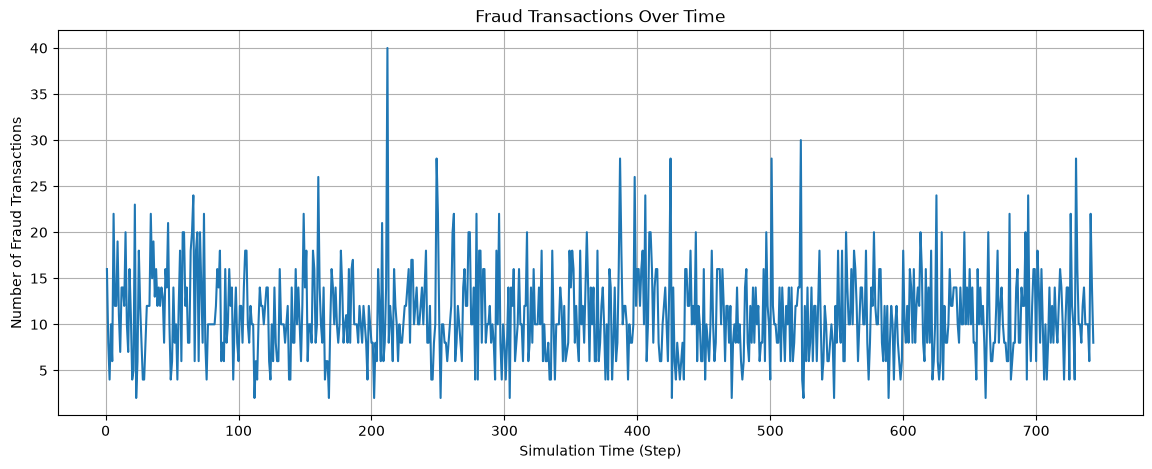

In [35]:
plt.figure(figsize=(14, 5))

plt.plot(
    fraud_by_step.index,
    fraud_by_step['fraud_count']
)

plt.title('Fraud Transactions Over Time')
plt.xlabel('Simulation Time (Step)')
plt.ylabel('Number of Fraud Transactions')
plt.grid(True)
plt.show()

In [36]:
fraud_by_step.sort_values(
    by='fraud_amount',
    ascending=False
).head(10)

,fraud_count,fraud_amount
step,,
387,28,1.472376e+08
646,20,1.245596e+08
730,28,1.150034e+08
425,28,1.102985e+08
440,18,1.064249e+08
212,40,1.043355e+08
398,26,9.247349e+07
160,26,8.887244e+07
617,16,8.860749e+07


In [37]:
high_risk_senders = fraud_transactions.groupby('nameOrig').agg(
    fraud_count=('isFraud', 'count'),
    total_fraud_amount=('amount', 'sum')
)

high_risk_senders.sort_values(
    by='total_fraud_amount',
    ascending=False
).head(10)

,fraud_count,total_fraud_amount
nameOrig,,
C99979309,1,10000000.0
C997532070,1,10000000.0
C1004068843,1,10000000.0
C1879989290,1,10000000.0
C576718894,1,10000000.0
C2062946234,1,10000000.0
C2064974440,1,10000000.0
C2065498878,1,10000000.0
C2068007279,1,10000000.0


In [38]:
high_risk_receivers = fraud_transactions.groupby('nameDest').agg(
    fraud_count=('isFraud', 'count'),
    total_fraud_amount=('amount', 'sum')
)

high_risk_receivers.sort_values(
    by='total_fraud_amount',
    ascending=False
).head(10)

,fraud_count,total_fraud_amount
nameDest,,
C668046170,2,10160088.68
C1250722530,1,10000000.00
C890563348,1,10000000.00
C125702772,1,10000000.00
C447852930,1,10000000.00
C397396936,1,10000000.00
C399450397,1,10000000.00
C39886288,1,10000000.00
C43869769,1,10000000.00


In [39]:
pd.crosstab(
    df['isFraud'],
    df['isFlaggedFraud'],
    margins=True
)

isFlaggedFraud,0,1,All
isFraud,,,
0,6354407,0,6354407
1,8197,16,8213
All,6362604,16,6362620


In [40]:
correctly_flagged = df[
    (df['isFraud'] == 1) &
    (df['isFlaggedFraud'] == 1)
].shape[0]

total_fraud = df['isFraud'].sum()

detection_rate = (correctly_flagged / total_fraud) * 100

detection_rate

np.float64(0.1948131011810544)

In [41]:
correct_predictions = (
    df['isFraud'] == df['isFlaggedFraud']
).sum()

accuracy = (correct_predictions / len(df)) * 100

accuracy

np.float64(99.87116942391656)

In [42]:
false_negatives = df[
    (df['isFraud'] == 1) &
    (df['isFlaggedFraud'] == 0)
].shape[0]

false_negatives

8197

In [43]:
true_positives = (
    (df['isFraud'] == 1) &
    (df['isFlaggedFraud'] == 1)
).sum()

false_positives = (
    (df['isFraud'] == 0) &
    (df['isFlaggedFraud'] == 1)
).sum()

precision = (
    true_positives / (true_positives + false_positives)
) * 100 if (true_positives + false_positives) > 0 else 0

precision

np.float64(100.0)

In [44]:
true_negatives = (
    (df['isFraud'] == 0) &
    (df['isFlaggedFraud'] == 0)
).sum()

false_positive_rate = (
    false_positives / (false_positives + true_negatives)
) * 100

false_positive_rate

np.float64(0.0)

In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    df['isFraud'],
    df['isFlaggedFraud']
)

cm

array([[6354407,       0],
       [   8197,      16]])

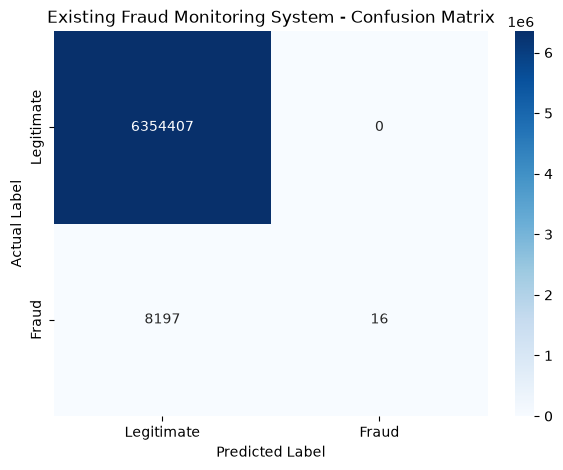

In [46]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate', 'Fraud'],
    yticklabels=['Legitimate', 'Fraud']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Existing Fraud Monitoring System - Confusion Matrix')

plt.show()

In [47]:
(df['amount'] < 0).sum()

np.int64(0)

In [48]:
(df['amount'] == 0).sum()

np.int64(16)

In [49]:
(df[['oldbalanceOrg', 'newbalanceOrig']] < 0).sum()

oldbalanceOrg     0
newbalanceOrig    0
dtype: int64

In [50]:
(df[['oldbalanceDest', 'newbalanceDest']] < 0).sum()

oldbalanceDest    0
newbalanceDest    0
dtype: int64

In [51]:
df['amount'].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999])

0.250    1.338957e+04
0.500    7.487194e+04
0.750    2.087215e+05
0.900    3.654233e+05
0.950    5.186342e+05
0.990    1.615979e+06
0.999    8.956798e+06
Name: amount, dtype: float64

In [52]:
df.nlargest(10, 'amount')[
    ['step', 'type', 'amount', 'nameOrig', 'nameDest', 'isFraud']
]

,step,type,amount,nameOrig,nameDest,isFraud
3686583,276,TRANSFER,92445516.64,C1715283297,C439737079,0
4060598,300,TRANSFER,73823490.36,C2127282686,C753026640,0
4146397,303,TRANSFER,71172480.42,C2044643633,C84111522,0
3946920,286,TRANSFER,69886731.30,C1425667947,C167875008,0
3911956,284,TRANSFER,69337316.27,C1584456031,C1472140329,0
3937152,286,TRANSFER,67500761.29,C811810230,C1757599079,0
4105338,302,TRANSFER,66761272.21,C420748282,C1073241084,0
3892529,284,TRANSFER,64234448.19,C1139847449,C65111466,0
3991638,298,TRANSFER,63847992.58,C300140823,C514940761,0
4143801,303,TRANSFER,63294839.63,C372535854,C1871605747,0


In [53]:
sender_activity = df.groupby('nameOrig').agg(
    total_transactions=('nameOrig', 'count'),
    total_amount=('amount', 'sum'),
    fraud_transactions=('isFraud', 'sum')
)

sender_activity.head()

,total_transactions,total_amount,fraud_transactions
nameOrig,,,
C1000000639,1,244486.46,0
C1000001337,1,3170.28,0
C1000001725,1,8424.74,0
C1000002591,1,261877.19,0
C1000003372,1,20528.65,0


In [54]:
sender_activity.sort_values(
    by='total_transactions',
    ascending=False
).head(10)

,total_transactions,total_amount,fraud_transactions
nameOrig,,,
C1832548028,3,313665.83,0
C1530544995,3,490535.09,0
C1065307291,3,113479.28,0
C1902386530,3,763712.79,0
C1784010646,3,436700.25,0
C1462946854,3,166791.43,0
C1677795071,3,244735.38,0
C1976208114,3,511130.35,0
C1999539787,3,290555.01,0


In [55]:
receiver_activity = df.groupby('nameDest').agg(
    total_transactions=('nameDest', 'count'),
    total_amount=('amount', 'sum'),
    fraud_transactions=('isFraud', 'sum')
)

receiver_activity.head()

,total_transactions,total_amount,fraud_transactions
nameDest,,,
C1000004082,6,2259324.39,0
C1000004940,13,2534004.05,0
C1000013769,13,6204082.94,0
C100001587,9,1404313.66,0
C1000015936,16,2267960.19,0


In [56]:
receiver_activity.sort_values(
    by='total_transactions',
    ascending=False
).head(10)

,total_transactions,total_amount,fraud_transactions
nameDest,,,
C1286084959,113,7.742894e+07,0
C985934102,109,4.242289e+07,0
C665576141,105,8.874938e+07,0
C2083562754,102,5.307394e+07,0
C248609774,101,4.068016e+07,0
C1590550415,101,4.320610e+07,0
C451111351,99,3.745303e+07,0
C1789550256,99,1.778853e+08,0
C1360767589,98,3.512129e+07,0


In [57]:
sender_frequency = df.groupby(['nameOrig', 'step']).size().reset_index(name='transaction_count')

sender_frequency.head()

,nameOrig,step,transaction_count
0,C1000000639,249,1
1,C1000001337,217,1
2,C1000001725,46,1
3,C1000002591,231,1
4,C1000003372,167,1


In [58]:
sender_frequency.sort_values(
    by='transaction_count',
    ascending=False
).head(10)

,nameOrig,step,transaction_count
1922214,C1584515358,180,2
1113091,C133857826,17,2
147302,C1044884182,229,2
203070,C1061931265,402,2
485003,C1147740514,40,2
986467,C1300281685,304,2
534064,C1162717140,15,2
1852956,C1563483633,186,2
2262480,C1687872323,187,2
1528829,C1464829026,307,2


In [6]:
sender_frequency = df.groupby(['nameOrig', 'step']).size().reset_index(name='transaction_count')

sender_frequency.head()

,nameOrig,step,transaction_count
0,C1000000639,249,1
1,C1000001337,217,1
2,C1000001725,46,1
3,C1000002591,231,1
4,C1000003372,167,1


In [7]:
sender_frequency.sort_values(
    by='transaction_count',
    ascending=False
).head(10)

,nameOrig,step,transaction_count
1922214,C1584515358,180,2
1113091,C133857826,17,2
147302,C1044884182,229,2
203070,C1061931265,402,2
485003,C1147740514,40,2
986467,C1300281685,304,2
534064,C1162717140,15,2
1852956,C1563483633,186,2
2262480,C1687872323,187,2
1528829,C1464829026,307,2


In [8]:
high_frequency_senders = sender_frequency[
    sender_frequency['transaction_count'] > 1
]

high_frequency_senders.shape

(47, 3)

In [9]:
multi_transaction_senders = high_frequency_senders['nameOrig'].unique()

df['isHighFrequencySender'] = df['nameOrig'].isin(
    multi_transaction_senders
)

pd.crosstab(
    df['isHighFrequencySender'],
    df['isFraud'],
    normalize='index'
) * 100

isFraud,0,1
isHighFrequencySender,,
False,99.870916,0.129084
True,100.000000,0.000000


In [10]:
df.groupby('isHighFrequencySender').agg(
    total_transactions=('isFraud', 'count'),
    fraud_transactions=('isFraud', 'sum'),
    unique_senders=('nameOrig', 'nunique')
)

,total_transactions,fraud_transactions,unique_senders
isHighFrequencySender,,,
False,6362526,8213,6353260
True,94,0,47


In [21]:
fraud_sender_frequency = (
    fraud_transactions.groupby('nameOrig')
    .size()
    .reset_index(name='fraud_transaction_count')
)

fraud_sender_frequency.sort_values(
    by='fraud_transaction_count',
    ascending=False
).head(10)

,nameOrig,fraud_transaction_count
0,C1000036340,1
1,C1000086512,1
2,C1000331499,1
3,C1000484178,1
4,C1000513158,1
5,C1000937208,1
6,C1001502110,1
7,C1001765380,1
8,C1001875185,1
9,C1002446735,1
